# Loading and plotting validation tracks from Matthew Preistley

Workflow:

1. **Define the region** we want storms from, and a larger **tracking domain** around it.
2. **Prepare the input field**: ERA5 850 hPa relative vorticity (`vo`), 6-hourly, 0.25°.
3. **Run the Hodges tracker** (`pystormtracker.HodgesTracker`) on the whole tracking domain.
4. **Post-process** the raw tracks: keep only real, mobile, long-lived cyclones (TRACK's RSPLICE filter) that affect the region.
5. **Plot** raw vs. kept tracks.
6. **Save** the filtered tracks and a per-track summary table.
7. **Sample other ERA5 fields** (t2m, msl, 10 m wind) along the kept tracks.

Helper functions live in `stormtracker.py`.

In [148]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import pandas as pd
import pystormtracker as pst
from pathlib import Path
import cartopy.crs as ccrs

import sys
import os

module_dir = (Path.cwd() / ".."/".." / "algorithms").resolve()
sys.path.insert(0,str(module_dir))
import validation as val
import processing as pro
import statistics_on_tracks as sot

import importlib
importlib.reload(val)  # pick up edits in validation.py without restarting the kernel
importlib.reload(pro)  # pick up edits in processing.py without restarting the kernel
importlib.reload(sot)  # pick up edits in statistic_on_tracks.py without restarting the kernel

import importlib


## 1. Region of interest and tracking domain

Boxes are given as `(lon_min, lon_max, lat_min, lat_max)` in degrees, longitudes in −180…180.

* **`REGION`** — where we want storms: the North Atlantic storm track and Northern Europe
  (60°W–30°E, 40°N–75°N). This box is only used *after* tracking, to select tracks.
* **`DOMAIN`** — the area actually given to the tracker. It is **larger than the region** on purpose:
  * the spatial taper (`taper_points`) and the regional DCT band-pass filter distort the field near the
    domain edges, giving spurious or displaced vorticity maxima there;
  * a storm that forms west of the region (e.g. off Newfoundland) and moves in should be tracked from its
    real genesis, not from where it first crosses the box. Otherwise lifetimes, genesis positions and
    peak intensities are biased.

So we track in the big box and select tracks that affect the small box, but keep each selected track
**whole** (including the parts outside the region) so its full life cycle is available.

> With the current file the buffer is 20° to the west, 10° to the east and south, but only 5° to the
> north (the data stop at 80°N). If you download more data, a domain like `(-100, 60, 20, 90)` gives
> a more comfortable buffer.

In [149]:
#Importing the data from the file
REGION = (-80, 20, 30, 80)   # smaller region for tracking, limited by the domain, 10 deg smaller
DOMAIN = (-90, 30, 20, 90)   # tracking domain (region + buffer), limited by the downloaded data
TIME_RANGE = ('1998-12-01 00:00:00', '1999-02-28 18:00:00')  # time range for the validation tracks

tracks_validation = val.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/validation_tracks_data/ERA5_19981999_TRACKS_FILTERED_pos.addmslp', start_time=TIME_RANGE[0], end_time=TIME_RANGE[1])



In [150]:
tracks_validation

,lon,lat,vorticity,mslp_lon,mslp_lat,mslp,track_id,time
obs,,,,,,,,
0,0.487187,45.558174,2.945488,NaN,NaN,1024.025,3,1998-12-01 00:00:00
1,-2.346924,44.636440,2.743430,359.6110,42.38197,1017.109,3,1998-12-01 06:00:00
2,-7.956207,39.646866,3.258656,NaN,NaN,1017.025,3,1998-12-01 12:00:00
3,-9.561157,37.609779,3.978987,NaN,NaN,1012.945,3,1998-12-01 18:00:00
4,-9.764160,36.040455,4.625281,352.7589,35.01079,1010.072,3,1998-12-02 00:00:00
...,...,...,...,...,...,...,...,...
8523,174.133652,85.109848,3.723335,NaN,NaN,1024.317,2562,1999-02-26 12:00:00
8524,161.192886,84.471527,3.298671,NaN,NaN,1028.030,2562,1999-02-26 18:00:00
8525,150.237457,83.856377,2.820443,NaN,NaN,1031.977,2562,1999-02-27 00:00:00


<GeoAxes: title={'center': 'Tracks'}>

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


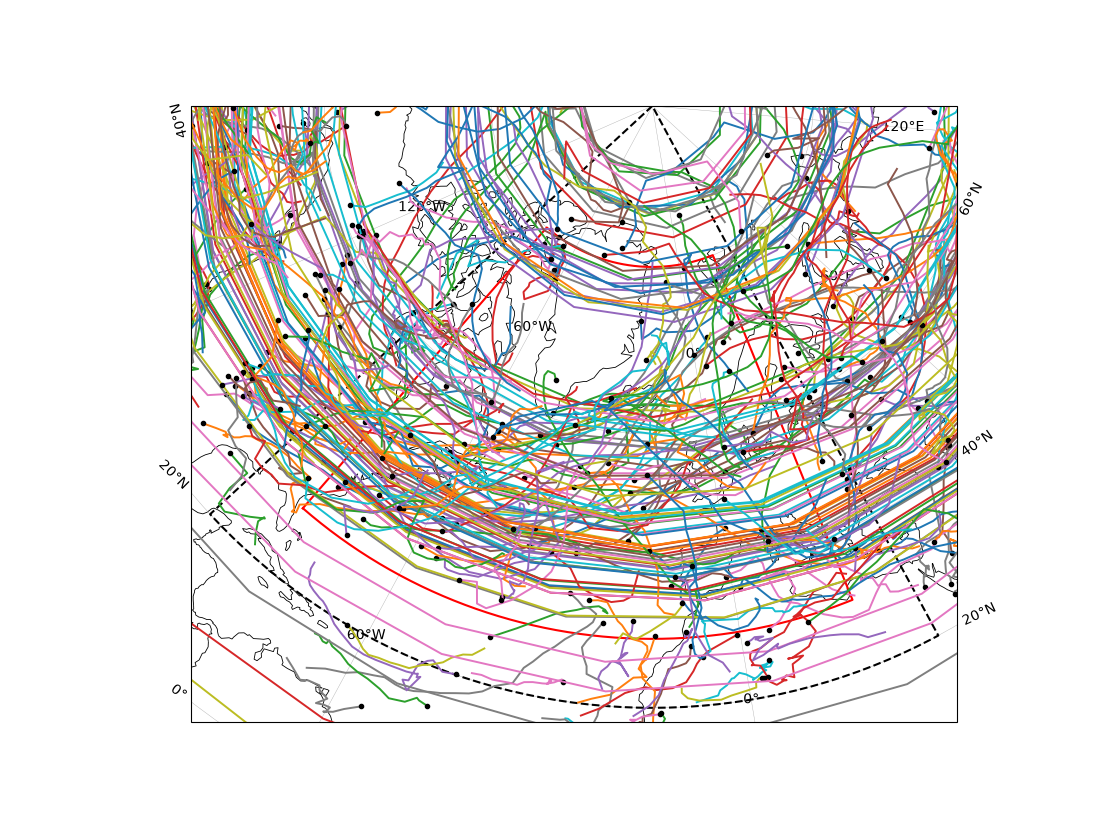

In [151]:
val.plot_regional_tracks(tracks_validation, region=REGION, domain=DOMAIN, object = False)

In [152]:
# import numpy as np
# import matplotlib.pyplot as plt
# import cartopy.crs as ccrs
# import cartopy.feature as cfeature
# #(west, east, south, north) 
# REGION = (-80, 20, 30, 80)   # lon_min, lon_max, lat_min, lat_max
# DOMAIN = (-90, 30, 20, 90)


# def in_region(ds, region):
#     """Boolean mask over `obs`: is the track point inside the region?"""
#     lon_min, lon_max, lat_min, lat_max = region
#     lon = st.wrap_lon(ds.lon)
#     return (lon >= lon_min) & (lon <= lon_max) & (ds.lat >= lat_min) & (ds.lat <= lat_max)


# def filter_tracks_by_region(ds, region, min_points=2):
#     """Keep only tracks with at least `min_points` points inside `region`.

#     Whole tracks are kept (including their points outside the region).
#     """
#     inside = in_region(ds, region)
#     counts = inside.groupby("track_id").sum()
#     keep_ids = counts.track_id.values[counts.values >= min_points]
#     idx = np.where(np.isin(ds.track_id.values, keep_ids))[0]
#     return ds.isel(obs=idx)


# def plot_tracks(ds, region=REGION, domain=DOMAIN, ax=None, date='Dec 1999'):
#     """Plot each track as a line, with the region and domain boxes."""
#     if ax is None:
#         fig = plt.figure(figsize=(10, 7))
#         ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=-15, central_latitude=55))

#     ax.set_extent([domain[0]-20, domain[1]+20, domain[2]-10, domain[3]], crs=ccrs.PlateCarree())
#     ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
#     ax.add_feature(cfeature.BORDERS, linewidth=0.3)
#     ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)

#     lon_all = st.wrap_lon(ds.lon).values
#     lat_all = ds.lat.values
#     ids = ds.track_id.values
#     for tid in np.unique(ids):
#         m = ids == tid
#         ax.plot(lon_all[m], lat_all[m], lw=1, alpha=0.8, transform=ccrs.PlateCarree())
#         ax.plot(lon_all[m][0], lat_all[m][0], "o", color="C1", markersize=4, transform=ccrs.PlateCarree())

#     # region box (red) and domain box (grey dashed)
#     for box, style in ((region, dict(color="red", lw=1.5)),
#                        (domain, dict(color="grey", lw=1, ls="--"))):
#         x0, x1, y0, y1 = box
#         ax.plot([x0, x1, x1, x0, x0], [y0, y0, y1, y1, y0],
#                 transform=ccrs.PlateCarree(), **style)

#     ax.set_title(f"{np.unique(ids).size} tracks in region {region} in {date}")
#     return ax

In [153]:
tracks_val, summary_val = val.postprocess_validation_tracks(tracks_validation, region=REGION, domain=DOMAIN, time_range=TIME_RANGE,
                       region_criterion="passes", min_points_in_region=1,
                       min_peak=None, max_frac_at_edge=0.5,
                       edge_buffer_deg=2.5, drop_time_truncated=False)

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


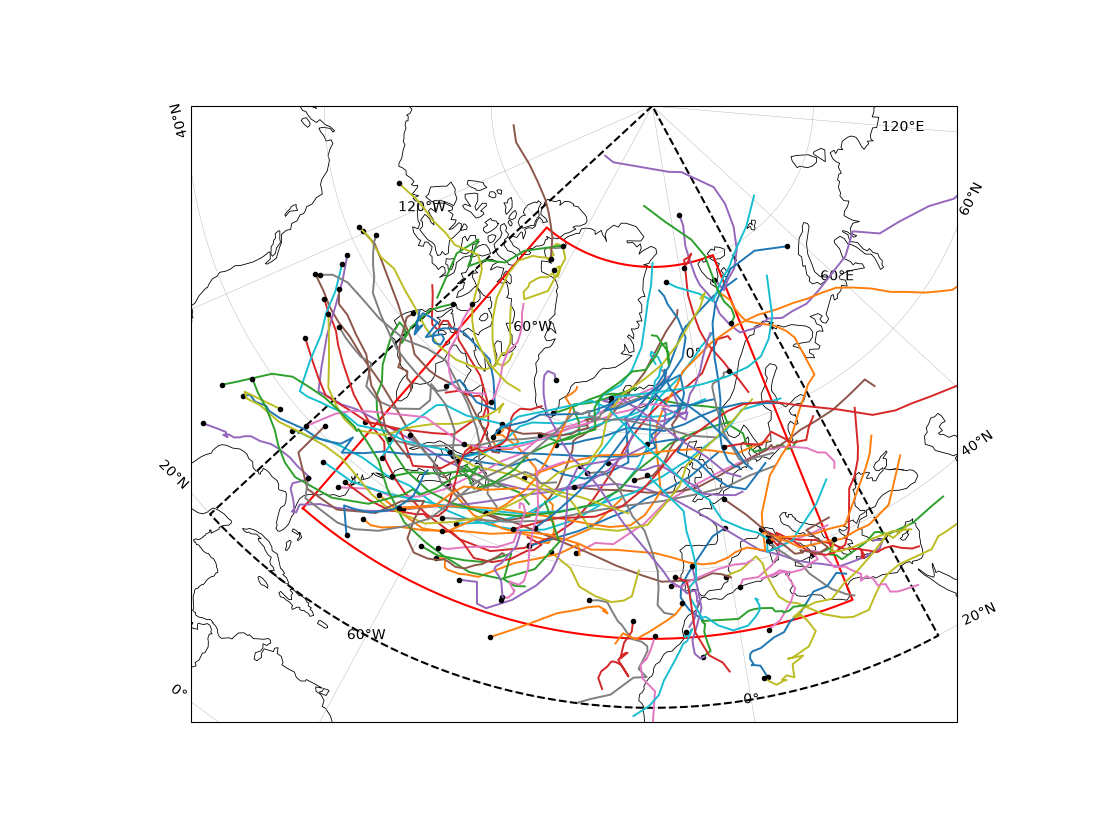

In [154]:
ax = val.plot_regional_tracks(tracks_val, region=REGION, domain=DOMAIN, summary = summary_val, object=False)

### Tracking and plotting 

In [155]:
ds = xr.open_dataset('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/data/19981999_DJF_vo.nc')
ds

<xarray.Dataset> Size: 389MB
Dimensions:         (valid_time: 720, pressure_level: 1, latitude: 281,
                     longitude: 481)
Coordinates:
  * valid_time      (valid_time) datetime64[ns] 6kB 1998-01-01 ... 1999-12-31...
    expver          (valid_time) <U4 12kB ...
  * pressure_level  (pressure_level) float64 8B 850.0
  * latitude        (latitude) float64 2kB 90.0 89.75 89.5 ... 20.5 20.25 20.0
  * longitude       (longitude) float64 4kB -90.0 -89.75 -89.5 ... 29.75 30.0
    number          int64 8B ...
Data variables:
    vo              (valid_time, pressure_level, latitude, longitude) float32 389MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-13T09:46 GRIB to CDM+CF via cfgrib-0.9.1...

In [156]:
ds = pro.prepare_tracking_field(ds, variable='vo',level =850, domain=DOMAIN)
ds = ds.sel(valid_time=slice(TIME_RANGE[0], TIME_RANGE[1]))
ds

<xarray.Dataset> Size: 195MB
Dimensions:     (valid_time: 360, latitude: 281, longitude: 481)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 3kB 1998-12-01 ... 1999-02-28T18:...
  * latitude    (latitude) float64 2kB 90.0 89.75 89.5 89.25 ... 20.5 20.25 20.0
  * longitude   (longitude) float64 4kB -90.0 -89.75 -89.5 ... 29.5 29.75 30.0
Data variables:
    vo          (valid_time, latitude, longitude) float32 195MB ...

In [157]:
# tracks = pro.hodges_tracker(input_file_path=ds, output_file_name='19981999_DJF_vo', track_variable='vo', min_track_points=10, taper_points=10, lmin=5,lmax=42,min_object_grid_points=18,
#                    object_threshold=None, exclude_boundary_extrema=False)

tracks = pst.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/trackjson/19981999_DJF_vo.trackjson')

In [158]:
tracks, summary, points = pro.postprocess_tracks(tracks, region=REGION, domain=DOMAIN, time_range=TIME_RANGE,
                       region_criterion="passes", min_points_in_region=1,
                       rsplice_min_points=8, rsplice_max_points=None,
                       rsplice_distance_degrees=10.0, rsplice_distance_mode="endpoint",
                       rsplice_cadence=np.timedelta64(6, "h"),
                       min_peak=None, max_frac_at_edge=0.5,
                       edge_buffer_deg=2.5, drop_time_truncated=False)

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


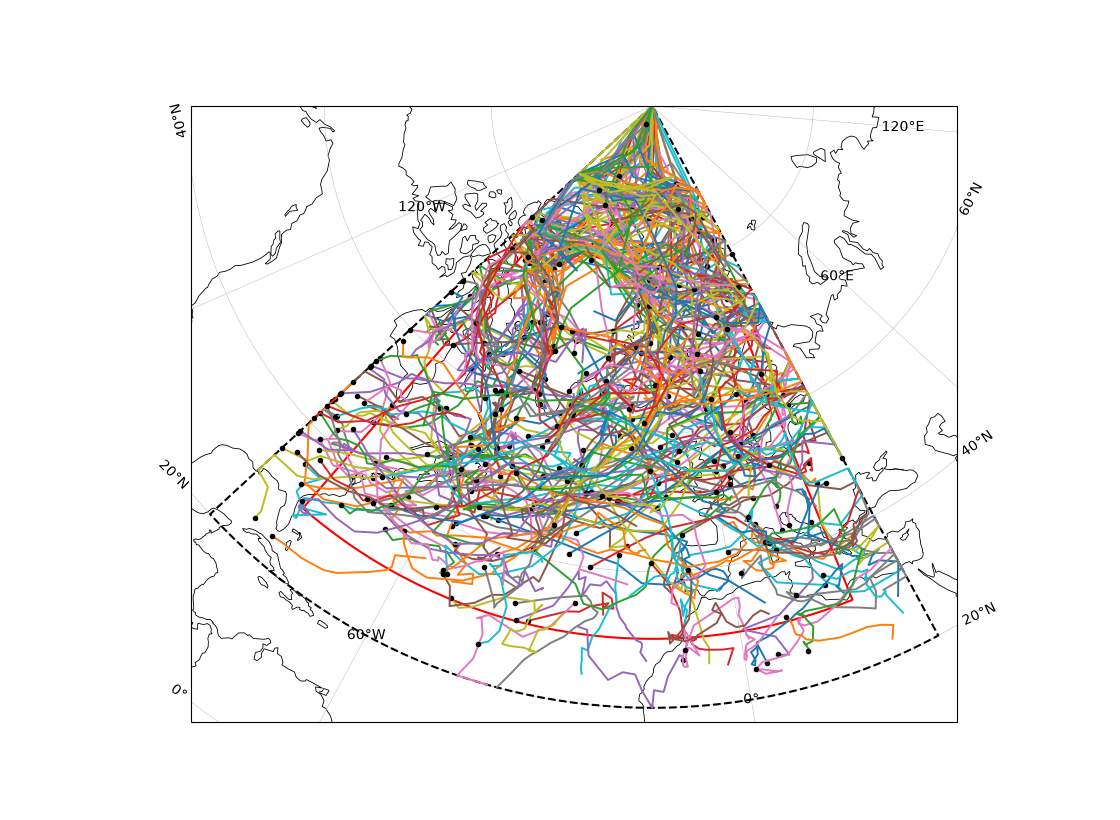

In [159]:
ax = val.plot_regional_tracks(tracks, region=REGION, domain=DOMAIN, summary = summary, object=True)


### Algorithm for comparing tracks

Specifically we want to find whether the tracks from priestley are present in our data.  

#### Pseudo-code

for track in validation_set
    record len (start, end) +- 1 day in each end (?) in time and (lat, lon) +- (5 deg?) for start and finish

same for our set, but without +-.

If our track is in BOTH recorded metrics: yes, match

else: no match



checks:

Structure:
I will create a new col in the summary of the validation pandas df.
This will contain a list of candidate tracks from our algorithm. 
Various checks will be made comparing time of genesis, genesis point, length, endpoint

First check:
sliding window of 24 hours.
Compare genisis points of these active storms if they are within 500 km save a list of track ids.


Select all tracks that are active within 24 hours.
Check the individual distances between points for these active locations
If the distance between storms are within 500 km they are the same storm


In [160]:
array_of_candidates = np.zeros(len(tracks_val.track_id.values))
array_of_candidates

array([0., 0., 0., ..., 0., 0., 0.], shape=(2024,))

In [161]:
#check if any track_ids in summary is nan:
summary

,track_id,n_points,start_time,end_time,lat_genesis,lon_genesis,lat_lysis,lon_lysis,path_km,n_in_region,...,starts_at_first_frame,ends_at_last_frame,rsplice_points,rsplice_displacement_deg,ok_rsplice,ok_region,ok_edge,ok_peak,ok_time,keep
0,1,10,1998-12-14 00:00:00,1998-12-16 06:00:00,79.50,-26.25,79.00,-34.50,3420.143276,3,...,False,False,10,1.616406,False,True,True,True,True,False
1,6,15,1998-12-14 18:00:00,1998-12-18 06:00:00,62.50,13.00,66.75,-39.50,3710.097454,15,...,False,False,15,22.189748,True,True,True,True,True,True
2,7,10,1998-12-14 00:00:00,1998-12-16 06:00:00,80.75,-84.75,81.50,-44.00,3430.868920,3,...,False,False,10,6.198256,False,True,True,True,True,False
3,8,10,1998-12-15 00:00:00,1998-12-17 06:00:00,54.25,-51.25,52.00,-22.25,2471.257060,10,...,False,False,10,17.421175,True,True,True,True,True,True
4,10,23,1998-12-11 00:00:00,1998-12-16 12:00:00,70.50,-61.25,61.00,-86.50,3136.439668,15,...,False,False,23,13.874497,True,True,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
482,4785,12,1999-02-21 18:00:00,1999-02-24 12:00:00,20.00,-20.00,25.00,-24.25,2041.082078,0,...,False,False,12,6.356213,False,False,True,True,True,False
483,4799,12,1999-02-22 12:00:00,1999-02-25 06:00:00,73.75,11.50,83.25,-27.00,4828.279993,1,...,False,False,12,11.724643,True,True,True,True,True,True
484,4803,10,1999-02-20 06:00:00,1999-02-22 12:00:00,71.25,21.00,75.75,-8.50,1424.400350,2,...,False,False,10,9.369333,False,True,True,True,True,False
485,4813,14,1999-02-20 06:00:00,1999-02-23 12:00:00,72.25,-53.25,76.50,-61.75,3029.920840,13,...,False,False,14,4.816682,False,True,True,True,True,False


In [162]:
summary_val.loc[0]

track_id                                   3
n_points                                   8
start_time               1998-12-01 00:00:00
end_time                 1998-12-02 18:00:00
lat_genesis                        45.558174
lon_genesis                         0.487187
lat_lysis                          32.335617
lon_lysis                          -6.001343
path_km                          1953.201698
n_in_region                                8
frac_at_edge                             0.0
duration_h                              42.0
separation_km                    1572.356627
genesis_in_region                       True
vorticity_peak                      4.645763
time_peak                1998-12-02 06:00:00
lat_peak                           34.762379
lon_peak                           -8.886871
peak_in_region                          True
starts_at_first_frame                   True
ends_at_last_frame                     False
ok_region                               True
ok_edge   

In [205]:
#creating time matching

time_window = pd.Timedelta(hours=12)

matches = []
for _, row in summary_val.iterrows():
    mask = summary["start_time"].between(row.start_time - time_window,
                                         row.start_time + time_window)
    matches.append(summary.loc[mask, "track_id"].dropna().tolist())

summary_val["matching_times_ids"] = matches




In [ ]:
# creating lat/lon matching

max_distance = 5000 #m

matches = []
for _, row in summary_val.iterrows():
    ids= row.matching_times_ids

    for i in ids:
        lat_i =summary[summary.track_id == i].lat_genesis


[27, 45, 52, 369, 469, 480, 504, 626, 633, 659, 665]
[27, 45, 52, 369, 469, 480, 504, 626, 633, 659, 665]
[27, 45, 52, 369, 469, 480, 504, 626, 633, 659, 665]
[27, 45, 52, 369, 469, 480, 504, 626, 633, 659, 665]
[27, 45, 52, 369, 469, 480, 504, 626, 633, 659, 665]
[27, 45, 52, 369, 469, 480, 504, 626, 633, 659, 665]
[27, 45, 52, 369, 469, 480, 504, 626, 633, 659, 665]
[27, 45, 52, 369, 469, 480, 504, 626, 633, 659, 665]
[27, 45, 52, 369, 469, 480, 504, 626, 633, 659, 665]
[27, 45, 52, 369, 469, 480, 504, 626, 633, 659, 665]
[27, 45, 52, 369, 469, 480, 504, 626, 633, 659, 665]
[27, 45, 52, 369, 469, 480, 504, 626, 633, 659, 665]
[27, 45, 52, 369, 469, 480, 504, 626, 633, 659, 665]
[52, 369, 633, 665]
[52, 369, 633, 665]
[52, 369, 633, 665]
[62, 553, 677]
[62, 553, 677]
[62, 553, 677]
[62, 553, 677]
[62, 533, 553, 677]
[533, 545, 668]
[533, 545, 668]
[533, 545, 668]
[116, 117, 119, 382, 387, 545, 667, 668, 688]
[116, 117, 119, 382, 387, 545, 667, 668, 688]
[116, 117, 119, 382, 387, 667, 

In [198]:
validate_track = summary_val.loc[0]
candidate_tracks = summary_val['matching_times_ids'].loc[0]


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


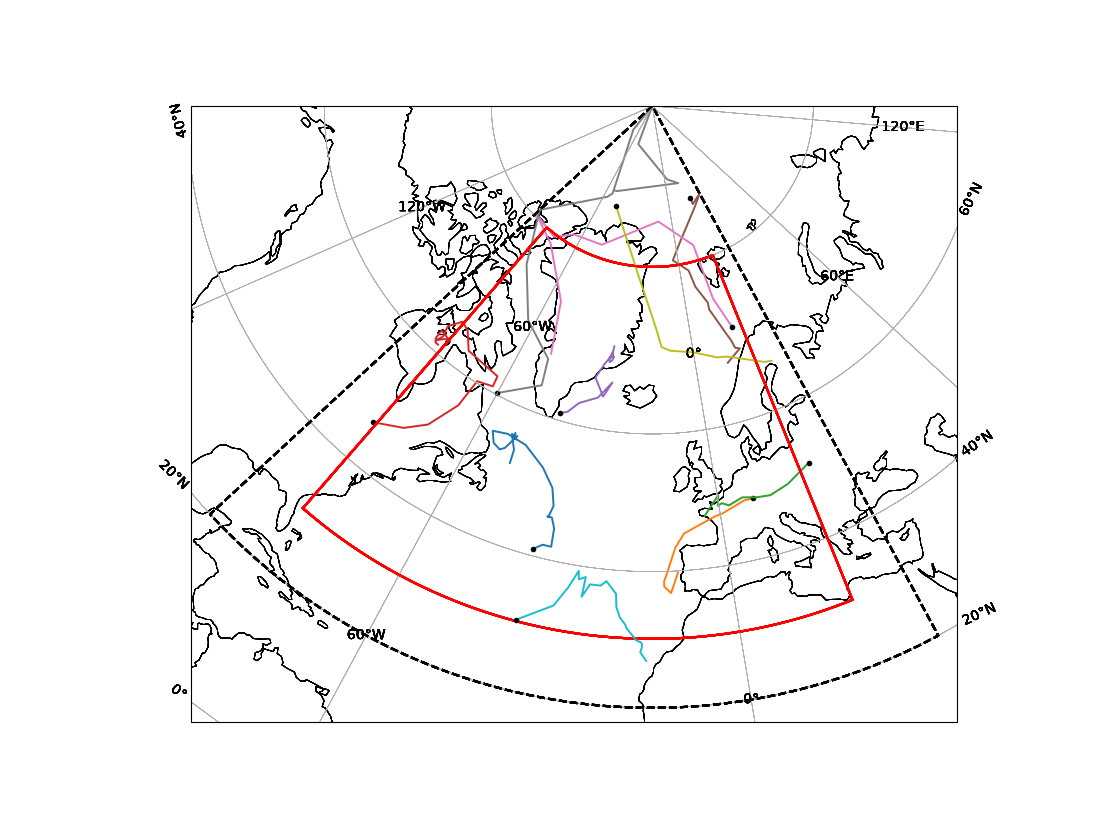

In [207]:

validate_track = summary_val.loc[10]
plot_validate_track = sot.select_track(tracks_val, validate_track.track_id)
candidate_tracks = summary_val['matching_times_ids'].loc[10]
ax = val.plot_regional_tracks(plot_validate_track, region=REGION, domain=DOMAIN, summary = summary_val, object=False)
for i in candidate_tracks:
    storm = sot.select_track(points, i)
    ax = val.plot_regional_tracks(storm, region=REGION, domain=DOMAIN, summary = summary, object=False, ax=ax)
